Linear Regression Diagramatic Representation

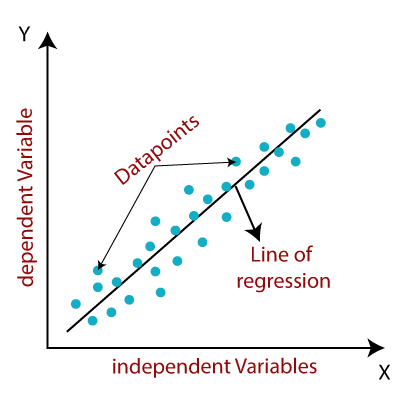

Naïve Bayes is a probabilistic supervised learning algorithm based on Bayes' Theorem.

It predicts the class that has the highest probability given the input features.

P(A) – Prior probability (what we believe before seeing evidence)
P(B|A) – Likelihood (how likely the evidence is if A is true)
P(B) – Overall probability of the evidence
P(A|B) – Posterior probability (updated belief after seeing the evidence)

Advantages
Very Fast

Works well on small datasets

Easy to implement

Excellent for text classification

Disadvantages

Assumes features are independent

Lower accuracy when features are highly correlated

Sensitive to rare categories

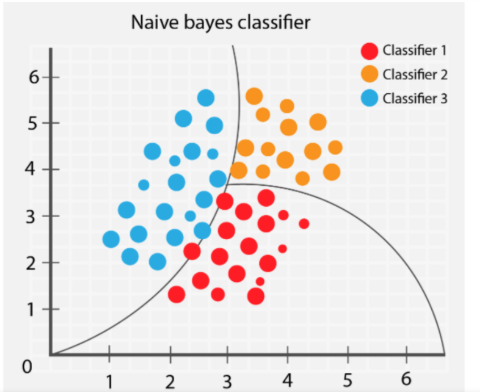

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/Teen_Mental_Health_Dataset.csv")

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

In [ ]:
features = [
    "daily_social_media_hours",
    "sleep_hours",
    "academic_performance",
    "stress_level",
    "anxiety_level",
    "addiction_level"
]

X = df[features]
y = df["depression_label"]

In [ ]:
# 80% → Training
# 20% → Testing
# random_state = 42 → Same split every time
# Stratify helps to maintain the class balance
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
nb_prediction = nb_model.predict(X_test)
print("Naive Bayes Accuracy")

print(accuracy_score(y_test, nb_prediction))
print(classification_report(
    y_test,
    nb_prediction
))
print(confusion_matrix(
    y_test,
    nb_prediction
))

Naive Bayes Accuracy
0.9916666666666667
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       234
           1       1.00      0.67      0.80         6

    accuracy                           0.99       240
   macro avg       1.00      0.83      0.90       240
weighted avg       0.99      0.99      0.99       240

[[234   0]
 [  2   4]]


In [ ]:
new_data = [[
    7,
    5,
    6,
    8,
    7,
    9
]]

prediction = nb_model.predict(new_data)

if prediction[0] == 1:
    print("Depressed")
else:
    print("Not Depressed")

Not Depressed


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(


KNN predicts the class by looking at the K nearest neighbors.

Advantages

Simple

No Training

Easy

Works well for small datasets

Disadvantages

Slow for large datasets

Sensitive to scaling

Sensitive to noise

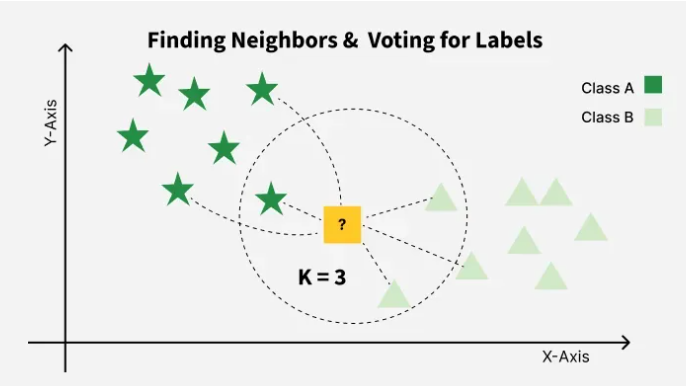

In [ ]:
knn = KNeighborsClassifier(
    n_neighbors=5
)
knn.fit(
    X_train,
    y_train
)
knn_prediction = knn.predict(X_test)
print("KNN Accuracy")

print(
    accuracy_score(
        y_test,
        knn_prediction
    )
)
print(
classification_report(
    y_test,
    knn_prediction
))
print(
confusion_matrix(
    y_test,
    knn_prediction
))


KNN Accuracy
0.9833333333333333
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       234
           1       0.75      0.50      0.60         6

    accuracy                           0.98       240
   macro avg       0.87      0.75      0.80       240
weighted avg       0.98      0.98      0.98       240

[[233   1]
 [  3   3]]


In [ ]:
new_data = [[
    7,
    5,
    6,
    8,
    7,
    9
]]

prediction = knn.predict(new_data)
if prediction[0] == 1:
    print("Depressed")
else:
    print("Not Depressed")

Depressed


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


SVM finds the best boundary that separates different classes.

Advantages

High Accuracy

Works well for High Dimensional Data

Effective on Small Dataset

Good for Text Classification

Disadvantages

Slow on Very Large Dataset

Needs Scaling

Parameter Selection Difficult

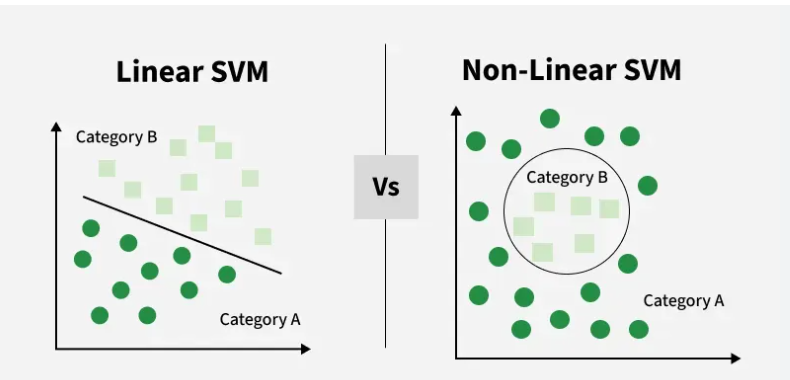

In [ ]:
svm = SVC(
    kernel="linear"
)
svm.fit(
    X_train,
    y_train
)
svm_prediction = svm.predict(
    X_test
)
print("SVM Accuracy")

print(
accuracy_score(
    y_test,
    svm_prediction
))
print(
classification_report(
    y_test,
    svm_prediction
))
print(
confusion_matrix(
    y_test,
    svm_prediction
))

SVM Accuracy
0.9833333333333333
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       234
           1       1.00      0.33      0.50         6

    accuracy                           0.98       240
   macro avg       0.99      0.67      0.75       240
weighted avg       0.98      0.98      0.98       240

[[234   0]
 [  4   2]]


In [ ]:
new_data = [[
    7,
    5,
    6,
    8,
    7,
    9
]]

prediction = svm.predict(new_data)

if prediction[0] == 1:
    print("Depressed")
else:
    print("Not Depressed")

Depressed


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


In [ ]:
results = pd.DataFrame({
    "Algorithm": [
        "Naive Bayes",
        "KNN",
        "SVM"
    ],
    "Accuracy": [
        accuracy_score(y_test, nb_prediction),
        accuracy_score(y_test, knn_prediction),
        accuracy_score(y_test, svm_prediction)
    ]
})

print(results)

     Algorithm  Accuracy
0  Naive Bayes  0.991667
1          KNN  0.983333
2          SVM  0.983333


| Feature               | Naïve Bayes                   | KNN                                | SVM                        |
| --------------------- | ----------------------------- | ---------------------------------- | -------------------------- |
| Learning Type         | Probability-based             | Distance-based                     | Boundary-based             |
| Main Idea             | Highest probability wins      | Majority vote of nearest neighbors | Best separating hyperplane |
| Training Speed        | Very Fast                     | Almost none (lazy learner)         | Moderate                   |
| Prediction Speed      | Fast                          | Slow (checks neighbors each time)  | Fast                       |
| Works Best For        | Text, spam, medical diagnosis | Small datasets                     | High-dimensional datasets  |
| Needs Feature Scaling | No (usually)                  | Yes                                | Yes                        |
| Sensitive to Noise    | Moderate                      | High                               | Moderate                   |


| Situation                    | Best Algorithm    |
| ---------------------------- | ----------------- |
| Spam Detection               | Naïve Bayes       |
| Email Classification         | Naïve Bayes       |
| Student Placement Prediction | KNN or SVM        |
| Medical Diagnosis            | Naïve Bayes / SVM |
| Image Classification         | SVM               |
| Face Recognition             | SVM               |
| Recommendation Systems       | KNN               |
